# jhgjg

In [1]:
variable = "jhgjg"

In [2]:
%matplotlib inline

import pandas as pd
import importlib
import re
import warnings
import calendar
import copy
import oceanval
import pickle

import glob
import geopandas as gpd
from oceanval.quiet_nc import nc
import os
import pickle
import numpy as np
import xarray as xr
from IPython.display import Markdown as md_markdown
from tqdm import tqdm
from IPython.core.interactiveshell import InteractiveShell
from oceanval.tidiers import tidy_info
from oceanval.map_land import land_below
InteractiveShell.ast_node_interactivity = "all"

try:
    lon_lim = None
    lat_lim = None
except:
    lon_lim = None
    lat_lim = None
if lon_lim is None:
    lon_lim = [-180, 180]
if lat_lim is None:
    lat_lim = [-90, 90]

try:
    concise = False
except:
    concise = False

# the depth ranges point matchups through the water column are summarised in
from oceanval.depths import DEFAULT_DEPTH_BINS, bin_depth, depth_labels, depth_ranges_text
try:
    depth_bins = the_depth_bins
except:
    depth_bins = DEFAULT_DEPTH_BINS
depth_levels = depth_labels(depth_bins)

# in one line
from oceanval.tidiers import fix_unit, df_display, md, md_basic

warnings.filterwarnings('ignore')

from oceanval.utils import restrict_r_to_conda
restrict_r_to_conda()

%load_ext rpy2.ipython

test_status = False


i_figure = 1
i_table = 1
stamp = nc.session_info["stamp"]
out = ".trackers/" + stamp
fast_plot = False
if not os.path.exists(".trackers"):
    os.makedirs(".trackers")
# save out as empty file
with open(out, 'w') as f:
    f.write("")

def bin_value(x, bin_res):
    return np.floor((x + bin_res / 2) / bin_res + 0.5) * bin_res - bin_res / 2

try:
    vv_name = variable
except:
    vv_name = "summary"
    variable = "summary"
Variable = variable.title()

In [3]:
import matplotlib.pyplot as plt
from IPython.display import display
from oceanval import analysis_plots as ap

# what analyze() saved, beside the report: the figures' code reads it from here
results_dir = "/users/modellers/maz/OceanVal_fvcom/oceanval_analysis/results"
info = ap.load(results_dir)
entry = ap.entry(info, variable)
name = entry["name"]
units = ap.unit_html(entry["units"])
# whether each figure has a button to copy the code that draws it
figure_code = bool(info.get("figure_code"))


def years_text(analysis):
    if analysis["start"] == analysis["end"]:
        return str(analysis["start"])
    return f"{analysis['start']}-{analysis['end']}"


def dates_text(analysis):
    """What the output is missing in an analysis's years."""
    dates = analysis["dates"]
    if dates["issues"]:
        return "Gaps in the output: " + " ".join(dates["issues"])
    return dates["summary"] + "."


def series_area_text(info, analysis):
    """What a long-term or seasonal series is the mean of."""
    where = "the model's domain"
    if info.get("lon_lim"):
        lon, lat = info["lon_lim"], info["lat_lim"]
        where += f" inside longitudes {lon[0]:g} to {lon[1]:g} and latitudes {lat[0]:g} to {lat[1]:g}"
    text = f"The series are area-weighted means over {where}"
    if analysis["regions"]:
        which = {"nwes": "the northwest European Shelf regions", "global": "the global regions"}.get(
            info.get("subregions"), "the regions of your own file"
        )
        text += f", and over each of {which} ({', '.join(analysis['regions'])})"
    if analysis["stations"]:
        text += ", and at the cell of the model's grid nearest each station"
    text += "."
    if analysis["notes"]:
        text += " " + " ".join(analysis["notes"])
    return text


def station_rows(saved, info):
    """A table of the stations and the model cells they are in."""
    rows = []
    for station, cell in saved["stations"].items():
        given = info["stations"][station]
        rows.append(
            {
                "Station": station,
                "Position": f"{given['lon']:.3f}, {given['lat']:.3f}",
                "Model cell": f"{cell['lon']:.3f}, {cell['lat']:.3f}",
                "Distance (km)": f"{cell['distance']:.1f}",
            }
        )
    return rows


def series_what(analysis, saved):
    """What a long-term series' figure shows: the annual mean, or its change."""
    window = analysis.get("window", 1)
    base = f"{window}-year rolling mean of the annual means" if window > 1 else "annual mean"
    what = {"absolute": base, "absolute_change": f"change in the {base}",
            "percentage_change": f"percentage change in the {base}"}[saved.get("show", "absolute")]
    return what[0].upper() + what[1:]


def series_shown_text(analysis):
    """How the long-term series are taken from the annual means, if they are not as they are."""
    window, show = analysis.get("window", 1), analysis.get("show", "absolute")
    text = ""
    if window > 1:
        before = f"the {window - 1} years before it" if window > 2 else "the year before it"
        first = f"the first {window - 1} years have" if window > 2 else "the first year has"
        text += (f"Each year is the mean of that year's annual mean and those of {before} (a {window}-year rolling mean), "
                 f"so {first} no value, nor has a year whose window has a year with no output. ")
    if show != "absolute":
        text += ("Each year is shown as its change from the first year with a value" +
                 (", in per cent of that value" if show == "percentage_change" else "") + ". ")
    return text


def regridded_text(regridded):
    if regridded:
        return " The model's grid was regridded to a regular lon-lat grid to draw it."
    return ""

In [4]:
parts = entry["model_variable"].split("+")
if len(parts) > 1:
    held = f"the sum of {', '.join(f'`{x}`' for x in parts[:-1])} and `{parts[-1]}`"
else:
    held = f"`{parts[0]}`"
described = f" ({entry['long_name']})" if entry["long_name"] and len(parts) == 1 else ""
in_units = f", in {units}" if units else ""
md(
    f"{name} is {held}{described} in the simulation's output{in_units}. It is read from the "
    f"{entry['files']} files named like `{entry['pattern']}`, which hold {entry['time_res_text']} "
    f"output from {entry['first']} to {entry['last']}."
)

jhgjg is `B1_fB1N1p` (bacteria release of DIP) in the simulation's output, in mmol Pm<sup>-3</sup>/d. It is read from the 12 files named like `amm7_1m_**_**_ptrc_T.nc`, which hold monthly output from 2013-01-16 to 2013-12-16.

In [5]:
clim = entry["climatology"]
md("## Climatology")

## Climatology

In [6]:
years = years_text(clim)
md(
    f"The climatology of {name} is its mean in each month of the year over {years}, read from "
    f"{clim['files']} file{'s' if clim['files'] != 1 else ''}, and the annual mean is the mean of the monthly means. "
    + dates_text(clim)
)

The climatology of jhgjg is its mean in each month of the year over 2013, read from 12 files, and the annual mean is the mean of the monthly means. All 12 months from 2013 to 2013 are there.

### Surface

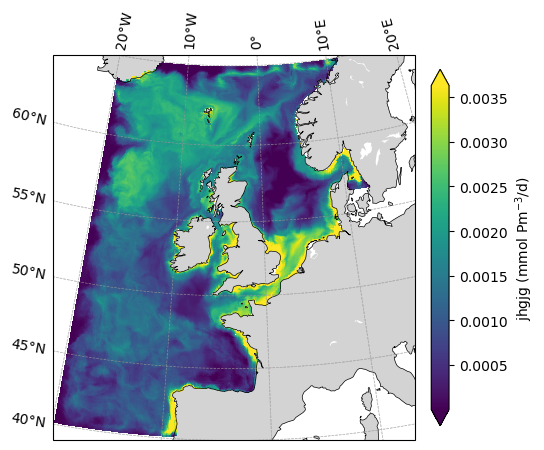

**Figure 1**: Annual mean surface jhgjg (mmol Pm<sup>-3</sup>/d), 2013. The colours run from the 2<sup>nd</sup> to the 98<sup>th</sup> percentile of the map, and arrows show that values go beyond them.

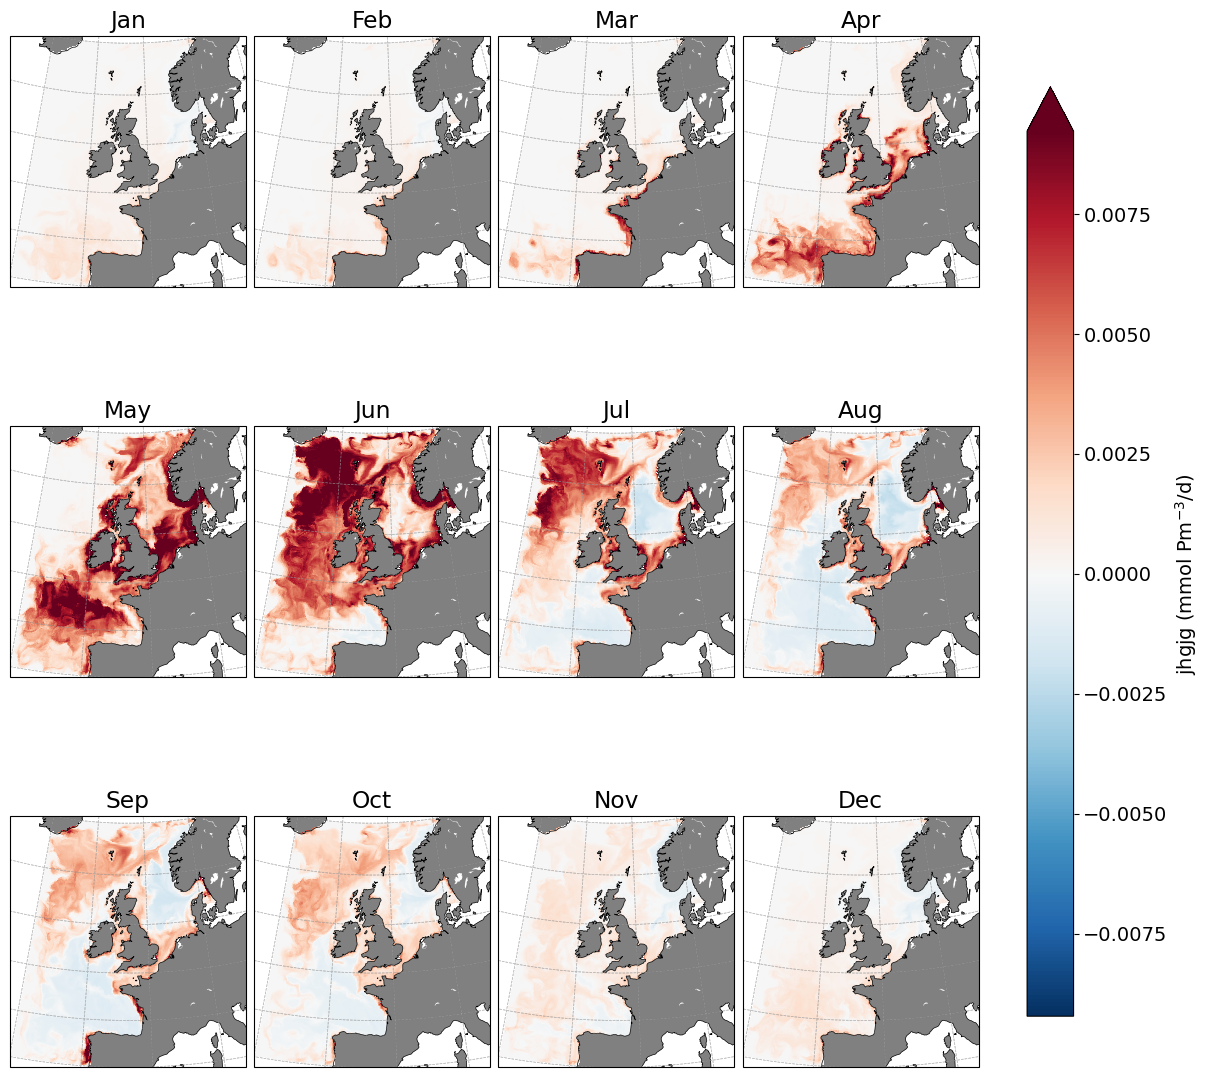

**Figure 2**: Mean surface jhgjg (mmol Pm<sup>-3</sup>/d) in each month of the year, 2013. All months share one colour scale, from the 2<sup>nd</sup> to the 98<sup>th</sup> percentile of all of them.

In [7]:
for layer, saved in clim["layers"].items():
    display(md(f"### {saved['title']}"))
    where = {"surface": "surface", "bottom": "bottom", "mean": "depth-averaged", "integral": "depth-integrated"}[layer]
    layer_units = ap.unit_html(saved["units"])
    drawn = ap.annual_map(results_dir, variable, layer)
    ap.show(drawn, figure_code, f"Figure {i_figure} on the {name} page")
    display(md(
        f"**Figure {i_figure}**: Annual mean {where} {name} ({layer_units}), {years}. "
        "The colours run from the 2nd to the 98th percentile of the map, and arrows show that values go beyond them."
        + regridded_text(drawn.regridded)
    ))
    i_figure += 1
    drawn = ap.monthly_maps(results_dir, variable, layer)
    ap.show(drawn, figure_code, f"Figure {i_figure} on the {name} page")
    display(md(
        f"**Figure {i_figure}**: Mean {where} {name} ({layer_units}) in each month of the year, {years}. "
        "All months share one colour scale, from the 2nd to the 98th percentile of all of them."
        + regridded_text(drawn.regridded)
    ))
    i_figure += 1

In [8]:
# delete all objects starting with ds
for name in dir():
    if name.startswith("ds"):
        del globals()[name]
for name in dir():
    if name.endswith("mask"):
        del globals()[name]
nc.cleanup()
for ff in nc.session.get_safe():
    nc.session.remove_safe(ff)
nc.cleanup()